# Solar Observations (1/3): Solar Magnetic Field

##Introduction
This is one of 3 notebooks you can use to view different types of solar imagary.  The other two notebooks view imagery of the Sun in extreme ultraviolet (EUV) and the white light imagery of the solar corona.  These other notebooks should be in the same directory.

Another notebook you will want to reference looks at the GOES X-Ray flux from the total disc od the Sun.

The goal of all these notebooks together is to compare the imagery of the Sun and see how the features seen in each type of view correspond to the features in the other views.

If you are working in a group, each member of the group may want to run a different and you can compare one to the other if the dates are aligned.  

### Loading Packages
Along with some standard packages, we will use [sunpy package](https://docs.sunpy.org/en/stable/tutorial/index.html) which is a community-developed, free and open-source solar data analysis environment. It is meant to provide the core functionality and tools to analyze solar data with Python.

*Note: During an change over period for data storage, the sunpy features that fetch the data have been moved to sunpy_cloudcatalog.  In the future, this will be included in the main package.*

In [1]:
%pip install -q sunpy[all] drms
import matplotlib.pyplot as plt
import sunpy.map
from sunpy.net import Fido
from sunpy.net import attrs as a
from sunpy.data.sample import HMI_LOS_IMAGE # Use sample data for a quick start
from astropy import units as u

%pip install -q sunpy_cloudcatalog
import sunpy_cloudcatalog
from sunpy.net import Fido, attrs as a
from sunpy_cloudcatalog import Bucket, DataID


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 971.6/971.6 kB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.9/110.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 75.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.8/105.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 350.3/350.3 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

HMI20110607_063211_los_lowres.fits:   0%|          | 0.00/8.40M [00:00<?, ?B/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.7/349.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.5/140.5 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.3/88.3 kB 8.3 MB/s eta 0:00:00


## Fetching Data
The next few cells download the image files.
- The first cell sets the date and time.  
- The next cell searches the data range for specific data sets.  These data sets are [described in detail](http://jsoc.stanford.edu/~priya/HMI/JSOC_Exportdata_Cheatsheet.html$0) on the Joint Science Operations Center (JSOC) for SDO.
- The last cell downloads the data based on the result of the serach. It will download all the files within the date range and store them in a list of files.

*Note: For now, you can use the email supplied in the first cell.  If you want to use this approach more broadly, you must have an [email address registered with JSOC](http://jsoc.stanford.edu/ajax/register_email.html) before you are allowed to make a request.*


In [2]:
import os
jsoc_email = "gross@bu.edu" # Make sure your JSOC email is registered
time_range = a.Time("2024-05-10 08:00:00", "2024-05-10 08:10:00")

In [3]:

query_visible = Fido.search(
    time_range,
    a.jsoc.Series('hmi.Ic_720s'), # Specify the exact JSOC series for HMI continuum intensity at a 720 second (12 min) cadance
    a.jsoc.Notify(jsoc_email)
)

print(query_visible) # Optional: inspect the search results

query_mag = Fido.search(
    time_range,
    a.jsoc.Series('hmi.M_720s'), # Specify the exact JSOC series for HMI photosphere magnetic field at a 45 second cadance
    a.jsoc.Notify(jsoc_email)
)
print(query_mag) # Optional: inspect the search results

Results from 1 Provider:

2 Results from the JSOCClient:
Source: http://jsoc.stanford.edu

         T_REC          TELESCOP   INSTRUME   WAVELNTH CAR_ROT
----------------------- -------- ------------ -------- -------
2024.05.10_08:00:00_TAI  SDO/HMI HMI_COMBINED   6173.0    2284
2024.05.10_08:12:00_TAI  SDO/HMI HMI_COMBINED   6173.0    2284


Results from 1 Provider:

2 Results from the JSOCClient:
Source: http://jsoc.stanford.edu

         T_REC          TELESCOP   INSTRUME   WAVELNTH CAR_ROT
----------------------- -------- ------------ -------- -------
2024.05.10_08:00:00_TAI  SDO/HMI HMI_COMBINED   6173.0    2284
2024.05.10_08:12:00_TAI  SDO/HMI HMI_COMBINED   6173.0    2284




In [4]:
downloaded_visible = Fido.fetch(query_visible)
print(f"Downloaded files: {downloaded_visible}")

downloaded_mag = Fido.fetch(query_mag)
print(f"Downloaded files: {downloaded_mag}")

INFO:sunpy:2 URLs found for download. Full request totaling 28MB


INFO: 2 URLs found for download. Full request totaling 28MB [sunpy.net.jsoc.jsoc]


Files Downloaded:   0%|          | 0/2 [00:00<?, ?file/s]

hmi.ic_720s.20240510_080000_TAI.3.continuum.fits:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

hmi.ic_720s.20240510_081200_TAI.3.continuum.fits:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

Downloaded files: ['/root/sunpy/data/hmi.ic_720s.20240510_080000_TAI.3.continuum.fits', '/root/sunpy/data/hmi.ic_720s.20240510_081200_TAI.3.continuum.fits']


... (2 outputs left out)

Files Downloaded:   0%|          | 0/2 [00:00<?, ?file/s]

hmi.m_720s.20240510_080000_TAI.3.magnetogram.fits:   0%|          | 0.00/13.9M [00:00<?, ?B/s]

hmi.m_720s.20240510_081200_TAI.3.magnetogram.fits:   0%|          | 0.00/13.9M [00:00<?, ?B/s]

Downloaded files: ['/root/sunpy/data/hmi.m_720s.20240510_080000_TAI.3.magnetogram.fits', '/root/sunpy/data/hmi.m_720s.20240510_081200_TAI.3.magnetogram.fits']


## Visualize the Data
This last cell uses the Sunpy "map" function to display the images in a standard python plot.  It will display the first (index =0) image in the list. You c


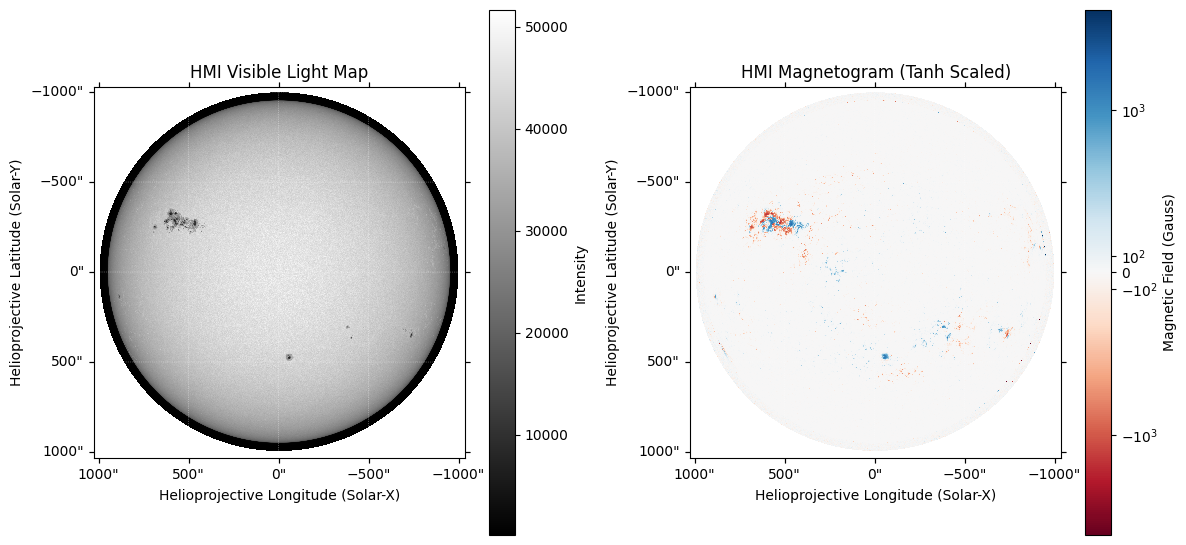

In [5]:
import numpy as np
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import sunpy.map # Removed this import as it's handled in cell bBvcmwTgnS8k

# Read the visible light file as a SunPy Map object
hmi_visible_map = sunpy.map.Map(downloaded_visible[0])

# Read the magnetogram file as a SunPy Map object
hmi_magnetogram_map = sunpy.map.Map(downloaded_mag[0])

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': hmi_visible_map})

# Plot the visible light map on the first subplot
im1 = hmi_visible_map.plot(axes=axes[0], cmap='gray') # 'gray' is a common colormap for visible light
axes[0].set_title('HMI Visible Light Map')
fig.colorbar(im1, ax=axes[0], orientation='vertical', label='Intensity') # Add colorbar for visible light

# Calculate symmetric limits for normalization for the magnetogram
abs_max_mag = np.nanmax(np.abs(hmi_magnetogram_map.data))
norm_mag = colors.SymLogNorm(linthresh=100, linscale=0.1, vmin=-abs_max_mag, vmax=abs_max_mag)

# Plot the magnetogram map on the second subplot
im2 = hmi_magnetogram_map.plot(axes=axes[1], cmap='RdBu', norm=norm_mag) # Changed colormap to RdBu for magnetic fields
axes[1].set_title('HMI Magnetogram (Tanh Scaled)')
fig.colorbar(im2, ax=axes[1], orientation='vertical', label='Magnetic Field (Gauss)') # Add colorbar for magnetogram

plt.tight_layout()

plt.show()

## Discusion 1: Examine the images
Review the scales on the two images.
- Use the Cell below to look at images from the next few days.
- What noticable difference are there in the images?

##Discussion 2: Compare the images to each other
- Is there a connection between the location of sunspots in the visible map, and location of strong magnetic field?
- Do all the strong magnetic field regions have sunspots?
- What do you notice about the polarity of the magnetic file regions?

## Discussion 3: Compare the images to EUV images (in the other notebook).
Compare the location of strong magnetic field regions to those of strong EUV emissions. Make sure the dates and times are aligned.
- What features in the EUV images correspond to either sunspots or magnetically active regions?



In [5]:
time_range = a.Time("2024-05-08 12:00:00", "2024-05-08 12:10:00") #set date and time for data search

query_visible = Fido.search(
    time_range,
    a.jsoc.Series('hmi.Ic_720s'), # Specify the exact JSOC series for HMI continuum intensity at a 720 second (12 min) cadance
    a.jsoc.Notify(jsoc_email)
)

print(query_visible) # Optional: inspect the search results

query_mag = Fido.search(
    time_range,
    a.jsoc.Series('hmi.M_720s'), # Specify the exact JSOC series for HMI photosphere magnetic field at a 45 second cadance
    a.jsoc.Notify(jsoc_email)
)
print(query_mag) # Optional: inspect the search results

downloaded_visible = Fido.fetch(query_visible)
print(f"Downloaded files: {downloaded_visible}")

downloaded_mag = Fido.fetch(query_mag)
print(f"Downloaded files: {downloaded_mag}")

# Read the visible light file as a SunPy Map object
hmi_visible_map = sunpy.map.Map(downloaded_visible[0])

# Read the magnetogram file as a SunPy Map object
hmi_magnetogram_map = sunpy.map.Map(downloaded_mag[0])

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': hmi_visible_map})

# Plot the visible light map on the first subplot
im1 = hmi_visible_map.plot(axes=axes[0], cmap='gray') # 'gray' is a common colormap for visible light
axes[0].set_title('HMI Visible Light Map')
fig.colorbar(im1, ax=axes[0], orientation='vertical', label='Intensity') # Add colorbar for visible light

# Calculate symmetric limits for normalization for the magnetogram
abs_max_mag = np.nanmax(np.abs(hmi_magnetogram_map.data))
norm_mag = colors.SymLogNorm(linthresh=100, linscale=0.1, vmin=-abs_max_mag, vmax=abs_max_mag)

# Plot the magnetogram map on the second subplot
im2 = hmi_magnetogram_map.plot(axes=axes[1], cmap='RdBu', norm=norm_mag) # Changed colormap to RdBu for magnetic fields
axes[1].set_title('HMI Magnetogram (Tanh Scaled)')
fig.colorbar(im2, ax=axes[1], orientation='vertical', label='Magnetic Field (Gauss)') # Add colorbar for magnetogram

plt.tight_layout()

plt.show()